# Battery optimisation

Optimal operation of a household battery with PV. The battery schedule is optimised week by week with a MILP model
(`battery_optimisation/model.py`) that minimises the cost of energy at day-ahead prices, the Slovenian network tariff
(energy per time block and power) and battery degradation. The bill is then compared for three cases:
no PV, PV only and PV with battery.

In [1]:
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from battery_optimisation import load_inputs, run_optimisation, calculate_bill

## Parameters

In [2]:
LOAD_FILE = 'load_household2.csv'  # load_household1.csv already includes a PV plant, use it with PV_SIZE = 0
PV_SIZE = 15  # kWp
PV_OPERATING_HOURS = 1100  # kWh/kWp per year

BATTERY_SIZE = 10  # kWh
BATTERY_POWER = 10  # kW
BATTERY_PRICE_PER_KWH = 100  # EUR/kWh
BATTERY_LIFE_CYCLES = 2000

# Network tariff: power price (EUR/kW) and energy price (EUR/kWh) per time block
block_power_prices = {1: 5.33444, 2: 1.08944, 3: 0.142570, 4: 0.00368, 5: 0.00000}
energy_grid_prices = {1: 0.01454, 2: 0.01389, 3: 0.01369, 4: 0.0133, 5: 0.01329}
MIN_SETTLEMENT_POWER = 5.  # kW

SOLVER = 'cbc'  # or 'glpk', 'appsi_highs'

## Input data

In [4]:
inputs = load_inputs(LOAD_FILE, PV_SIZE, PV_OPERATING_HOURS)
print(f"{inputs.index[0]} - {inputs.index[-1]}")
inputs.describe().round(2)

2025-01-10 16:00:00 - 2026-01-10 16:00:00


,load,pv,price,block
count,35041.00,35041.00,35041.00,35041.00
mean,0.69,1.92,104.74,2.86
std,0.59,3.00,53.47,1.10
min,0.00,0.00,-126.46,1.00
25%,0.31,0.00,84.11,2.00
50%,0.46,0.00,104.28,3.00
75%,0.86,2.98,128.00,4.00
max,6.19,12.10,561.75,5.00


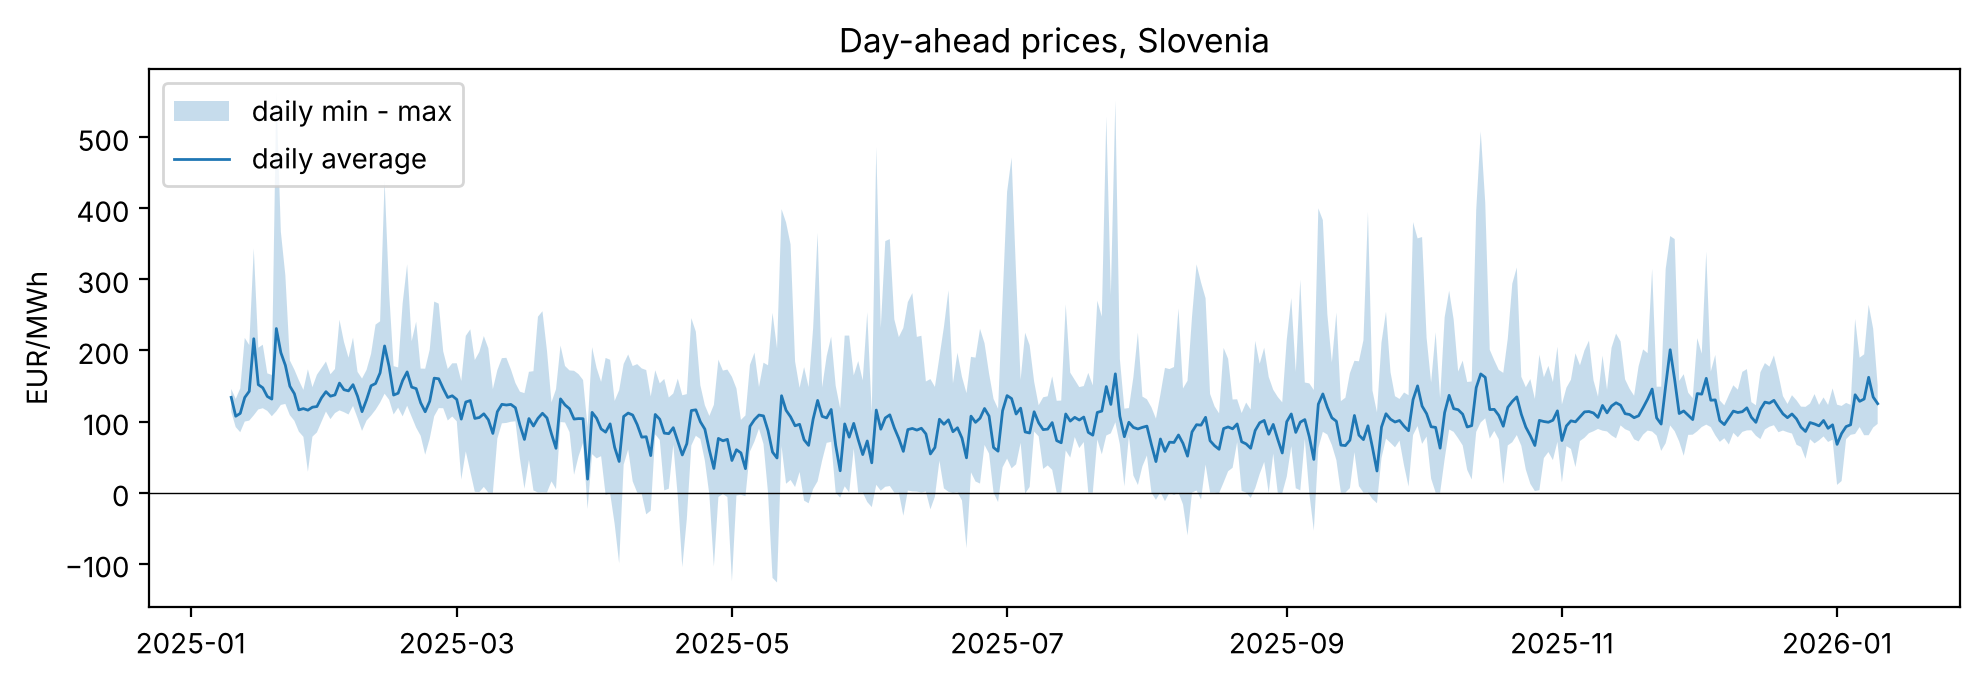

In [5]:
daily_price = inputs['price'].resample('D').agg(['mean', 'min', 'max'])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between(daily_price.index, daily_price['min'], daily_price['max'], alpha=0.25, label='daily min - max')
ax.plot(daily_price.index, daily_price['mean'], lw=1, label='daily average')
ax.axhline(0, color='k', lw=0.5)
ax.set_ylabel('EUR/MWh')
ax.set_title('Day-ahead prices, Slovenia')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('../docs/prices.png', dpi=120)

## Optimisation

In [6]:
df_res = run_optimisation(inputs, BATTERY_SIZE, BATTERY_POWER, BATTERY_SIZE * BATTERY_PRICE_PER_KWH,
                          BATTERY_LIFE_CYCLES, energy_grid_prices, block_power_prices,
                          min_settlement_power=MIN_SETTLEMENT_POWER, solver=SOLVER)

Week 2025-01-10 took 0.50 seconds


Week 2025-01-17 took 0.74 seconds


Week 2025-01-24 took 0.56 seconds


Week 2025-01-31 took 0.50 seconds


Week 2025-02-07 took 0.93 seconds


Week 2025-02-14 took 0.62 seconds


... (42 outputs left out)

Week 2025-12-12 took 0.64 seconds


Week 2025-12-19 took 0.29 seconds


Week 2025-12-26 took 0.38 seconds


Week 2026-01-02 took 0.65 seconds


## Bill and savings

The optimisation runs week by week, the bill is calculated afterwards for every month (the power charge uses the monthly peak) and summed over the whole period.

In [7]:
period = inputs.loc[df_res.index]
grid_cases = {
    'No PV': period['load'],
    'PV': period['load'] - period['pv'],
    'PV + battery': df_res['grid_power'],
}
monthly_bills = {
    name: calculate_bill(grid, period['price'], period['block'], energy_grid_prices, block_power_prices,
                         MIN_SETTLEMENT_POWER)
    for name, grid in grid_cases.items()
}
bills = pd.DataFrame({name: bill.sum() for name, bill in monthly_bills.items()}).T

# Battery degradation, the same cost as in the objective
charging = df_res['power'].clip(lower=0).sum() / 4
discharging = -df_res['power'].clip(upper=0).sum() / 4
battery_cycles = (charging + discharging) / 2 / BATTERY_SIZE
bills['battery_degradation'] = 0.
bills.loc['PV + battery', 'battery_degradation'] = (battery_cycles / BATTERY_LIFE_CYCLES *
                                                    BATTERY_SIZE * BATTERY_PRICE_PER_KWH)
bills['total'] = bills[['energy', 'network_energy', 'network_power', 'battery_degradation']].sum(axis=1)

weeks = len(df_res) // (96 * 7)
print(f"Analysed period: {weeks} weeks, battery cycles: {battery_cycles:.0f}")
print(f"Savings of the battery (PV + battery vs PV): {bills.loc['PV', 'total'] - bills.loc['PV + battery', 'total']:.0f} EUR")
bills.round(0)

Analysed period: 52 weeks, battery cycles: 346
Savings of the battery (PV + battery vs PV): 342 EUR


,energy,network_energy,network_power,total,battery_degradation
No PV,626.0,83.0,334.0,1043.0,0.0
PV,-428.0,43.0,325.0,-61.0,0.0
PV + battery,-949.0,54.0,319.0,-403.0,173.0


In [8]:
# Monthly savings of the battery (PV + battery vs PV, without battery degradation)
monthly_savings = pd.DataFrame({name: bill['total'] for name, bill in monthly_bills.items()})
monthly_savings['battery savings'] = monthly_savings['PV'] - monthly_savings['PV + battery']
monthly_savings.round(0)

,No PV,PV,PV + battery,battery savings
date_time,,,,
2025-01,65.0,24.0,3.0,21.0
2025-02,85.0,7.0,-20.0,27.0
2025-03,74.0,-12.0,-51.0,39.0
2025-04,77.0,8.0,-47.0,55.0
2025-05,87.0,-15.0,-79.0,64.0
2025-06,63.0,-40.0,-105.0,65.0
2025-07,85.0,-92.0,-140.0,48.0
2025-08,72.0,-16.0,-66.0,49.0
2025-09,85.0,-22.0,-80.0,58.0


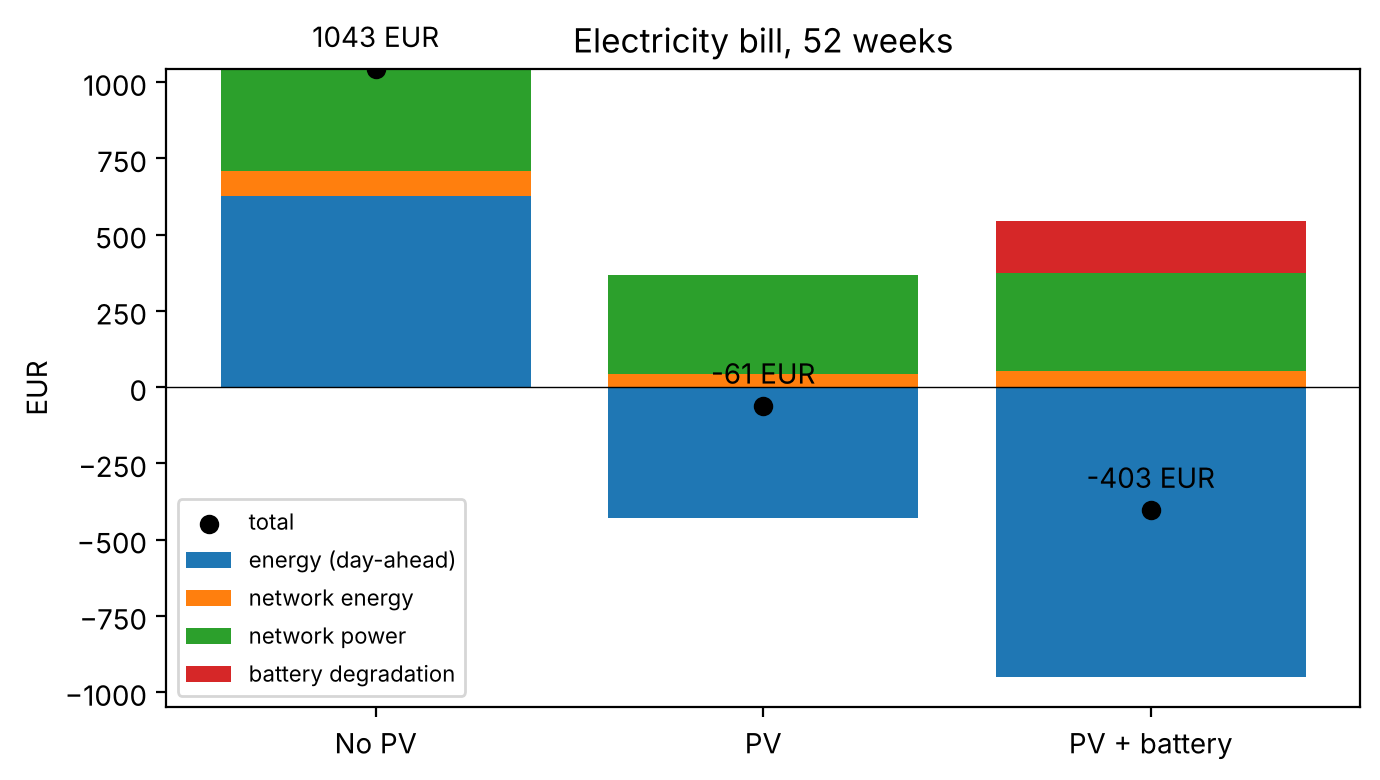

In [9]:
parts = ['energy', 'network_energy', 'network_power', 'battery_degradation']
labels = ['energy (day-ahead)', 'network energy', 'network power', 'battery degradation']

fig, ax = plt.subplots(figsize=(7, 4))
bottom_pos = np.zeros(len(bills))
bottom_neg = np.zeros(len(bills))
for part, label in zip(parts, labels):
    values = bills[part].values
    bottom = np.where(values >= 0, bottom_pos, bottom_neg)
    ax.bar(bills.index, values, bottom=bottom, label=label)
    bottom_pos += np.clip(values, 0, None)
    bottom_neg += np.clip(values, None, 0)
ax.scatter(bills.index, bills['total'], color='k', zorder=3, label='total')
for x, total in zip(bills.index, bills['total']):
    ax.annotate(f"{total:.0f} EUR", (x, total), textcoords='offset points', xytext=(0, 8), ha='center')
ax.axhline(0, color='k', lw=0.5)
ax.set_ylabel('EUR')
ax.set_title(f'Electricity bill, {weeks} weeks')
ax.legend(fontsize=8, loc='lower left')
fig.tight_layout()
fig.savefig('../docs/savings.png', dpi=120)

## One week of operation

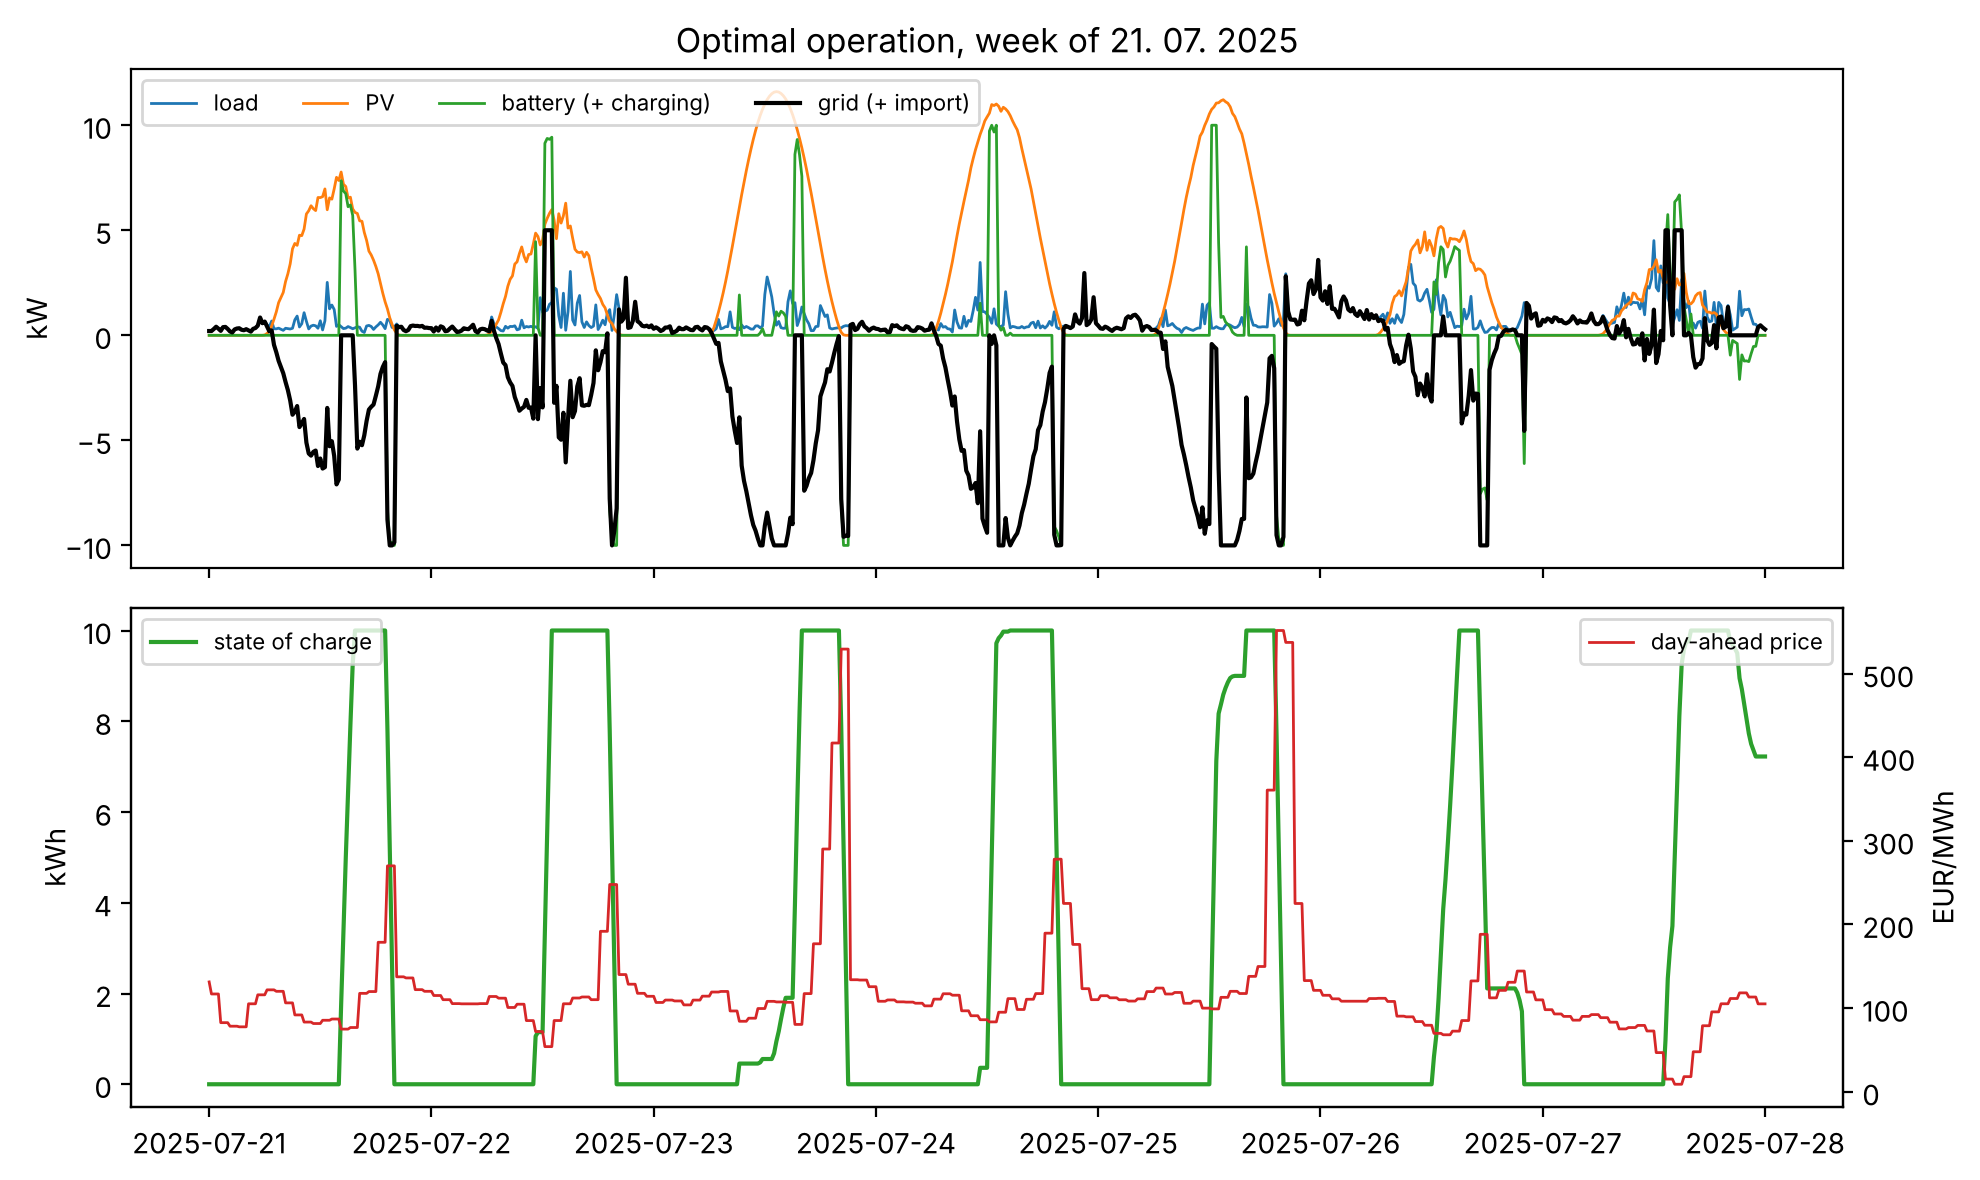

In [10]:
# Week with the largest daily price spread
spread = period['price'].resample('W').apply(lambda x: (x.max() - x.min()))
week_start = spread.idxmax() - pd.Timedelta(days=6)
week = df_res.loc[week_start:week_start + pd.Timedelta(days=7)]
week_prices = period.loc[week.index, 'price']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(week.index, week['load'], lw=1, label='load')
ax1.plot(week.index, week['limited_production'], lw=1, label='PV')
ax1.plot(week.index, week['power'], lw=1, label='battery (+ charging)')
ax1.plot(week.index, week['grid_power'], lw=1.5, color='k', label='grid (+ import)')
ax1.set_ylabel('kW')
ax1.legend(fontsize=8, ncol=4, loc='upper left')
ax2.plot(week.index, week['soc'], color='tab:green', label='state of charge')
ax2.set_ylabel('kWh')
ax3 = ax2.twinx()
ax3.plot(week.index, week_prices, color='tab:red', lw=1, label='day-ahead price')
ax3.set_ylabel('EUR/MWh')
ax2.legend(loc='upper left', fontsize=8)
ax3.legend(loc='upper right', fontsize=8)
ax1.set_title(f'Optimal operation, week of {week_start:%d. %m. %Y}')
fig.tight_layout()
fig.savefig('../docs/week.png', dpi=120)